# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NourhanFarag/nourhan-flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

### Signal Audit Plan

**Lane:** Refresh / Content Opportunity Scoring

**Unit of analysis:** One content page.

**Prediction cutoff:** 2026-03-14

**Historical feature window:** 2026-03-01 to 2026-03-14

**Future observation window:** 2026-03-15 to 2026-03-28

**Signals to investigate:**

1. Historical impressions — search visibility and opportunity.
2. Historical CTR — potential click-through weakness.
3. Content age — potential relationship with future performance.

**Method:**

First inspect feature distributions, missingness, and heavy tails.
Then compare historical signals with future observed outcomes.

Future-window measurements are used only for evaluating signals,
never as historical prediction features.

**Known limitations:**

- Missing GSC coverage is not equivalent to zero performance.
- Position encoding remains uncertain.
- Any review proxy is a heuristic, not ground-truth refresh need.
- Associations do not prove causation.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ML-06 Audit Frame: (317443, 10)

Historical Feature Distributions


,count,mean,std,min,50%,90%,95%,99%,max,missing_pct
prev_14d_impressions,150444.0,797.36,2545.97,1.0,101.00,1921.00,3625.70,10771.57,144869.0,52.61
prev_14d_ctr,150444.0,0.45,3.78,0.0,0.00,0.66,1.18,5.30,100.0,52.61
prev_14d_avg_position,150444.0,15.55,17.83,0.0,8.02,40.05,56.53,80.64,310.0,52.61
content_age_days,317443.0,199.59,115.48,0.0,209.00,351.00,395.00,461.00,477.0,0.00



Pages with future GSC observations: 158293


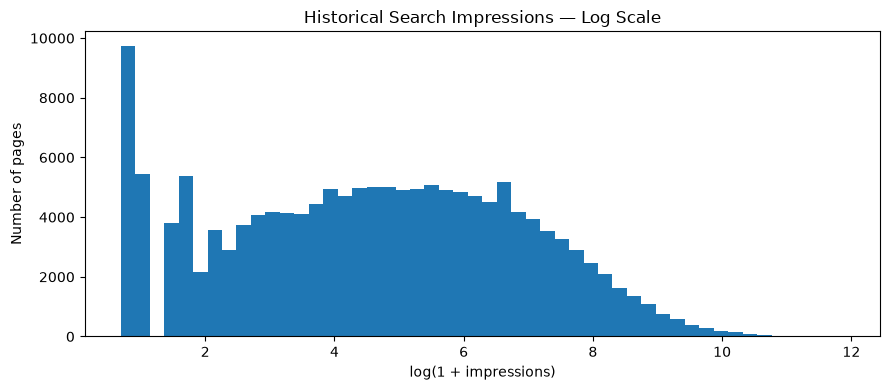

In [1]:
import os
import getpass
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Connect securely to Hugging Face
HF_TOKEN = os.environ.get("HF_TOKEN")

if not HF_TOKEN:
    HF_TOKEN = getpass.getpass("Hugging Face READ token: ")

con = duckdb.connect()

safe_token = HF_TOKEN.replace("'", "''")

con.execute(
    f"CREATE OR REPLACE SECRET hf "
    f"(TYPE huggingface, TOKEN '{safe_token}')"
)

REL = "hf://datasets/FlyRank/internship-warehouse"

MARCH_DAILY = (
    f"read_parquet("
    f"'{REL}/fact_content_daily_performance/month=2026-03/*.parquet'"
    f")"
)

DIM_CONTENT = f"read_parquet('{REL}/dim_content.parquet')"

# One warehouse scan for historical and future measurements
signal_frame = con.sql(f"""
WITH windows AS (
    SELECT
        client_hash_id,
        content_hash_id,

        COUNT(*) FILTER (
            WHERE report_date <= DATE '2026-03-14'
        ) AS historical_rows,

        COUNT(*) FILTER (
            WHERE report_date <= DATE '2026-03-14'
              AND gsc_data_available IS TRUE
        ) AS prev_available_days,

        COUNT(*) FILTER (
            WHERE report_date >= DATE '2026-03-15'
              AND gsc_data_available IS TRUE
        ) AS future_available_days,

        SUM(
            CASE
                WHEN report_date <= DATE '2026-03-14'
                 AND gsc_data_available IS TRUE
                THEN COALESCE(gsc_impressions, 0)
                ELSE 0
            END
        ) AS prev_impressions,

        SUM(
            CASE
                WHEN report_date <= DATE '2026-03-14'
                 AND gsc_data_available IS TRUE
                THEN COALESCE(gsc_clicks, 0)
                ELSE 0
            END
        ) AS prev_clicks,

        SUM(
            CASE
                WHEN report_date <= DATE '2026-03-14'
                 AND gsc_data_available IS TRUE
                THEN COALESCE(gsc_sum_position, 0)
                ELSE 0
            END
        ) AS prev_sum_position,

        SUM(
            CASE
                WHEN report_date >= DATE '2026-03-15'
                 AND gsc_data_available IS TRUE
                THEN COALESCE(gsc_impressions, 0)
                ELSE 0
            END
        ) AS future_impressions,

        SUM(
            CASE
                WHEN report_date >= DATE '2026-03-15'
                 AND gsc_data_available IS TRUE
                THEN COALESCE(gsc_clicks, 0)
                ELSE 0
            END
        ) AS future_clicks

    FROM {MARCH_DAILY}

    WHERE report_date BETWEEN DATE '2026-03-01'
                          AND DATE '2026-03-28'

    GROUP BY client_hash_id, content_hash_id
)

SELECT
    w.client_hash_id,
    w.content_hash_id,

    CASE
        WHEN w.prev_available_days > 0
        THEN w.prev_impressions
    END AS prev_14d_impressions,

    CASE
        WHEN w.prev_impressions > 0
        THEN 100.0 * w.prev_clicks / w.prev_impressions
    END AS prev_14d_ctr,

    CASE
        WHEN w.prev_impressions > 0
        THEN w.prev_sum_position / w.prev_impressions
    END AS prev_14d_avg_position,

    DATE_DIFF(
        'day',
        c.content_created_date,
        DATE '2026-03-14'
    ) AS content_age_days,

    w.prev_available_days,
    w.future_available_days,

    -- Future observations: evaluation only
    CASE
        WHEN w.future_available_days > 0
        THEN w.future_impressions
    END AS future_14d_impressions,

    CASE
        WHEN w.future_impressions > 0
        THEN 100.0 * w.future_clicks / w.future_impressions
    END AS future_14d_ctr

FROM windows AS w

INNER JOIN {DIM_CONTENT} AS c
    ON w.content_hash_id = c.content_hash_id

WHERE w.historical_rows > 0
  AND c.content_created_date IS NOT NULL
  AND c.content_created_date <= DATE '2026-03-14'
""").df()

assert not signal_frame[
    ["client_hash_id", "content_hash_id"]
].duplicated().any()

print("ML-06 Audit Frame:", signal_frame.shape)

# Distribution statistics
features = [
    "prev_14d_impressions",
    "prev_14d_ctr",
    "prev_14d_avg_position",
    "content_age_days",
]

distribution_summary = (
    signal_frame[features]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T
)

distribution_summary["missing_pct"] = (
    signal_frame[features].isna().mean() * 100
).round(2)

print("\nHistorical Feature Distributions")
display(distribution_summary.round(2))

print(
    "\nPages with future GSC observations:",
    int(signal_frame["future_available_days"].gt(0).sum())
)

# Visualize skew in historical impressions
observed_impressions = (
    signal_frame["prev_14d_impressions"].dropna()
)

plt.figure(figsize=(9, 4))
plt.hist(
    np.log1p(observed_impressions),
    bins=50
)

plt.title("Historical Search Impressions — Log Scale")
plt.xlabel("log(1 + impressions)")
plt.ylabel("Number of pages")
plt.tight_layout()
plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

### Signal Test Findings

**Test 1 — Historical Impressions**
- Hypothesis: Historical visibility persists.
- Sample: 139,565 pages observed in both windows.
- Spearman correlation: 0.9266.
- Verdict: CONFIRMED.
- Interpretation: Historical impressions strongly track future
  visibility, but do not directly prove refresh need.

**Test 2 — Historical CTR**
- Hypothesis: Historical CTR is associated with future CTR.
- Sample: 69,853 pages with at least 100 impressions in both windows.
- Spearman correlation: 0.5053.
- Verdict: CONFIRMED.
- Interpretation: CTR has moderate directional signal.
  Pages with higher historical CTR generally show stronger
  future CTR and click presence.

**Test 3 — Content Age**
- Hypothesis: Older content experiences more future decline.
- Sample: 75,382 pages with at least 100 historical impressions.
- Overall decline rate: 35.66%.
- Age 0–90 days: 38.19% decline.
- Age 91–180 days: 45.80% decline.
- Age 181–365 days: 30.20% decline.
- Age 366+ days: 28.49% decline.
- Verdict: MIXED.
- Interpretation: Decline rates are non-monotonic, and the
  oldest pages actually show lower decline rates.
  Content age alone is not a reliable refresh-priority rule.

These are observational associations, not causal findings.
Results apply to the selected measurable cohorts.

In [2]:
# Future measurements are used for evaluation only.

# Only compare pages observed in both windows.
both = signal_frame.loc[
    signal_frame["prev_available_days"].gt(0)
    & signal_frame["future_available_days"].gt(0)
].copy()

# Normalize exposure by GSC-observed days.
both["prev_imp_per_day"] = (
    both["prev_14d_impressions"]
    / both["prev_available_days"]
)

both["future_imp_per_day"] = (
    both["future_14d_impressions"]
    / both["future_available_days"]
)

print("Pages observed in both windows:", len(both))

# --------------------------------------------------
# TEST 1: Historical impressions vs future visibility
# --------------------------------------------------

test1_corr = both["prev_imp_per_day"].corr(
    both["future_imp_per_day"],
    method="spearman"
)

print("\nTEST 1 — Impressions")
print("Hypothesis: Historical visibility persists.")
print("Sample size:", len(both))
print("Spearman correlation:", round(test1_corr, 4))


# --------------------------------------------------
# TEST 2: Historical CTR vs future CTR
# --------------------------------------------------

# Minimum volume in both windows reduces CTR noise.
# 100 impressions is an analysis threshold, not
# a final production eligibility rule.

test2 = both.loc[
    both["prev_14d_impressions"].ge(100)
    & both["future_14d_impressions"].ge(100)
].copy()

test2_corr = test2["prev_14d_ctr"].corr(
    test2["future_14d_ctr"],
    method="spearman"
)

test2["historical_ctr_group"] = pd.cut(
    test2["prev_14d_ctr"],
    bins=[-0.001, 0, 1, np.inf],
    labels=["0%", "(0%, 1%]", ">1%"]
)

ctr_results = (
    test2.groupby(
        "historical_ctr_group",
        observed=False
    )
    .agg(
        pages=("future_14d_ctr", "size"),
        median_future_ctr=("future_14d_ctr", "median"),
        future_click_presence_pct=(
            "future_14d_ctr",
            lambda x: 100 * x.gt(0).mean()
        )
    )
    .round(2)
)

print("\nTEST 2 — CTR")
print("Hypothesis: Historical CTR predicts future CTR.")
print("Sample size:", len(test2))
print("Spearman correlation:", round(test2_corr, 4))
display(ctr_results)


# --------------------------------------------------
# TEST 3: Content age vs future impression decline
# --------------------------------------------------

test3 = both.loc[
    both["prev_14d_impressions"].ge(100)
].copy()

# Illustrative 20% decline threshold, not a
# confirmed label of content needing refresh.
test3["future_decline_20pct"] = (
    test3["future_imp_per_day"]
    < 0.8 * test3["prev_imp_per_day"]
)

test3["age_group"] = pd.cut(
    test3["content_age_days"],
    bins=[-1, 90, 180, 365, np.inf],
    labels=[
        "0-90 days",
        "91-180 days",
        "181-365 days",
        "366+ days"
    ]
)

age_results = (
    test3.groupby("age_group", observed=False)
    .agg(
        pages=("future_decline_20pct", "size"),
        decline_rate_pct=(
            "future_decline_20pct",
            lambda x: 100 * x.mean()
        )
    )
    .round(2)
)

print("\nTEST 3 — Content Age")
print("Hypothesis: Older content declines more often.")
print("Sample size:", len(test3))
print(
    "Overall decline rate:",
    round(100 * test3["future_decline_20pct"].mean(), 2),
    "%"
)
display(age_results)

Pages observed in both windows: 139565

TEST 1 — Impressions
Hypothesis: Historical visibility persists.
Sample size: 139565
Spearman correlation: 0.9266

TEST 2 — CTR
Hypothesis: Historical CTR predicts future CTR.
Sample size: 69853
Spearman correlation: 0.5053


,pages,median_future_ctr,future_click_presence_pct
historical_ctr_group,,,
0%,25683,0.00,30.82
"(0%, 1%]",40090,0.19,77.00
>1%,4080,0.78,87.92



TEST 3 — Content Age
Hypothesis: Older content declines more often.
Sample size: 75382
Overall decline rate: 35.66 %


,pages,decline_rate_pct
age_group,,
0-90 days,24284,38.19
91-180 days,14776,45.80
181-365 days,28801,30.20
366+ days,7521,28.49


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

### Flag-Linked Test Findings

**Flag-like rule:** Visible pages with low historical CTR.

**Hypothesis:** Pages with historical CTR below 0.5%
are more likely to continue experiencing low CTR.

**Eligible pages:** 32,525.

**Results:**
- Low historical CTR: 25,263 pages.
- Future low-CTR rate: 89.68%.
- Reference group: 7,262 pages.
- Reference future low-CTR rate: 44.11%.
- Difference: 45.57 percentage points.

**Verdict: CONFIRMED within the tested cohort.**

Historical low CTR is strongly associated with persistent
future low CTR in this selected population.

**Limitations:**
- This is an observational association, not causal evidence.
- It does not prove that a content refresh will improve CTR.
- The rule is an analytical approximation, not an exact
  reproduction of a production FlyRank flag.
- The position encoding remains uncertain.
- Future impression eligibility limits generalization
  to pages available for scoring at prediction time.

In [3]:
# Historical-only candidate rule; future data is evaluation only.

flag_test = both.loc[
    both["prev_14d_impressions"].ge(500)
    & both["future_14d_impressions"].ge(100)
    & both["prev_14d_avg_position"].gt(0)
    & both["prev_14d_avg_position"].le(20)
].copy()

# 14-day adaptation of a visible, low-CTR review rule.
flag_test["ctr_candidate"] = np.where(
    flag_test["prev_14d_ctr"] < 0.5,
    "Low historical CTR",
    "Reference: CTR >= 0.5%"
)

# Future outcome, used ONLY for evaluation.
flag_test["future_low_ctr"] = (
    flag_test["future_14d_ctr"] < 0.5
)

flag_results = (
    flag_test.groupby("ctr_candidate")
    .agg(
        pages=("future_low_ctr", "size"),
        future_low_ctr_pct=(
            "future_low_ctr",
            lambda x: 100 * x.mean()
        ),
        median_future_ctr=(
            "future_14d_ctr", "median"
        )
    )
    .round(2)
)

print("ML-06 — Flag-Linked CTR Test")
print("Eligible pages:", len(flag_test))
display(flag_results)

assert len(flag_results) == 2, (
    "Both candidate and reference groups are required."
)

ML-06 — Flag-Linked CTR Test
Eligible pages: 32525


,pages,future_low_ctr_pct,median_future_ctr
ctr_candidate,,,
Low historical CTR,25263,89.68,0.15
Reference: CTR >= 0.5%,7262,44.11,0.55


## 4. What this means in practice

### Practical Recommendation

Historical impressions and CTR provide useful signals for
identifying content performance patterns, but neither
independently proves that a page needs refreshing.

Content teams can prioritize investigating visible pages
with persistently low CTR, while avoiding simple age-based
rules because older content did not consistently decline more.

These results support review prioritization, not automatic
content changes. Any production rule should be validated
against actual editorial outcomes and monitored over time.

In [4]:
low_rate = flag_results.loc[
    "Low historical CTR", "future_low_ctr_pct"
]

reference_rate = flag_results.loc[
    "Reference: CTR >= 0.5%", "future_low_ctr_pct"
]

difference_pp = round(low_rate - reference_rate, 2)

assert len(flag_test) == flag_results["pages"].sum()

print("Final Flag-Linked Test Summary")
print("Low historical CTR group:", low_rate, "%")
print("Reference group:", reference_rate, "%")
print("Difference:", difference_pp, "percentage points")
print("Verdict: CONFIRMED within the tested cohort")

Final Flag-Linked Test Summary
Low historical CTR group: 89.68 %
Reference group: 44.11 %
Difference: 45.57 percentage points
Verdict: CONFIRMED within the tested cohort


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.